# Producción agrícola municipal: Evaluaciones Agropecuarias (EVA) 2006–2025

Las EVA registran, para cada municipio, cultivo y periodo, el área sembrada, el área cosechada, la producción y el rendimiento. La serie viene en dos tablas: la del Ministerio de Agricultura (2006–2018) y la de la UPRA (2019–2025). Este cuaderno las descarga, les pone los mismos nombres de columna y las une en una sola base.

|  |  |
|---|---|
| **Entidades** | Ministerio de Agricultura y Desarrollo Rural (2006–2018) y UPRA (2019–2025) |
| **Conjuntos** | [`2pnw-mmge`](https://www.datos.gov.co/d/2pnw-mmge) (MADR) y [`uejq-wxrr`](https://www.datos.gov.co/d/uejq-wxrr) (UPRA, base agrícola) |
| **Una fila es** | un cultivo en un municipio y un periodo (semestre A o B para cultivos transitorios, año para los permanentes) |
| **Cobertura** | todo el país, por municipio |
| **Periodo** | 2006 a 2025 |
| **Tamaño total** | 206.068 filas (MADR) + 166.732 filas (UPRA) = 372.800 (consultado el 31/10/2026) |
| **Actualización** | anual; la tabla UPRA se cargó el 28/08/2026 |
| **Requisitos** | ninguno (token de datos.gov.co opcional) |
| **Tiempo de descarga** | un departamento: segundos · todo el país: 1 a 2 minutos |

**Cómo usar este cuaderno**

1. Lea la ficha y la tabla de variables para saber qué va a descargar.
2. Ajuste la celda **«Parámetros que usted puede ajustar»** (sección 2). Es la única celda que necesita cambiar.
3. Ejecute todo (*Entorno de ejecución → Ejecutar todas* en Colab, o *Run All* en Jupyter). La base queda en la carpeta `datos/`.

Las salidas guardadas en este cuaderno salen de una **muestra pequeña** (los valores por defecto de los parámetros), para que usted vea cómo es la base antes de descargarla completa.

## Qué trae la base



| Columna | Qué es | Tipo |
|---|---|---|
| `fuente` | MADR (2006–2018) o UPRA (2019–2025) | categórica |
| `cod_dpto`, `departamento`, `cod_mpio`, `municipio` | Departamento y municipio (códigos DANE) | texto |
| `grupo`, `subgrupo`, `cultivo` | Clasificación del cultivo: p. ej. CEREALES → ARROZ | categórica |
| `ciclo` | TRANSITORIO, PERMANENTE o ANUAL | categórica |
| `anio`, `periodo` | Año y periodo (p. ej. `2021A`) | número, texto |
| `area_sembrada`, `area_cosechada` | Hectáreas sembradas y cosechadas | número |
| `produccion_t` | Producción en toneladas | número |
| `rendimiento` | Toneladas por hectárea cosechada | número |

Los textos se pasan a mayúsculas y sin tildes para que las dos tablas coincidan (`Café` y `CAFE` quedan como `CAFE`).

## Ideas para un modelo de machine learning

| Tarea | Variable objetivo | Predictoras posibles |
|---|---|---|
| Regresión | `rendimiento` (t/ha) de un cultivo | municipio, departamento, año, ciclo, área sembrada; clima de los cuadernos 10, 11 o 14 |
| Clasificación | ¿El rendimiento del municipio supera la mediana del cultivo? | las mismas |
| Pronóstico | producción anual de un cultivo en un departamento | la propia serie y sus rezagos |
| Agrupamiento | municipios según su mezcla de cultivos | proporción del área por grupo de cultivo |

**Cuidados antes de modelar**

- **Fuga de información:** `rendimiento` = `produccion_t` / `area_cosechada`. Si predice el rendimiento, no use la producción ni el área cosechada.
- En 2019 cambió la fuente (MADR → UPRA) y la forma de nombrar cultivos: revise que la serie no salte por esa razón (`fuente`).
- El rendimiento tiene valores extremos (cultivos con muy poca área): use el logaritmo o recorte los extremos.
- Valide **en el tiempo** (entrene hasta un año y evalúe los siguientes), no al azar.

## 1. Instalación

En Colab casi todo viene instalado; esta celda agrega lo que falte.

In [1]:
import importlib.util, subprocess, sys

PAQUETES = [("requests", "requests"), ("pandas", "pandas"), ("pyarrow", "pyarrow"), ("matplotlib", "matplotlib"), ("openpyxl", "openpyxl")]   # (módulo, paquete de pip)
faltan = [p for m, p in PAQUETES if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
print("Librerías listas" + (f"; se instalaron: {', '.join(faltan)}" if faltan else ""))

Librerías listas


## 2. Parámetros que usted puede ajustar

`CULTIVO` busca el texto dentro del nombre del cultivo, sin importar tildes ni mayúsculas (`"cafe"` encuentra `CAFE` y `Café`).

> **Token opcional.** datos.gov.co funciona sin clave, pero con un *app token* gratuito las descargas grandes fallan menos: cree una cuenta en datos.gov.co → *Developer Settings* → *Create New App Token*, y antes de ejecutar escriba `os.environ["SOCRATA_APP_TOKEN"] = "su_token"`.

In [2]:
DEPARTAMENTO = "Meta"   # con o sin tildes. None = todo el país
CULTIVO      = None     # texto dentro del nombre del cultivo, p. ej. "arroz", "cafe", "palma". None = todos
ANIO_INI     = 2006     # desde 2006
ANIO_FIN     = 2025     # hasta 2025

FORMATO = "parquet"          # "parquet" (liviano y rápido), "csv" o "excel"
BAJAR_AL_COMPUTADOR = False  # en Colab, True descarga el archivo a su computador al terminar

## 3. Funciones de apoyo

No necesita cambiarlas. Descargan por páginas, reintentan si la conexión falla, resumen la base y la guardan en el formato elegido.

In [3]:
import os, re, time, unicodedata, requests, numpy as np, pandas as pd
from pathlib import Path
from IPython.display import display

DATOS = Path("datos"); DATOS.mkdir(exist_ok=True)   # aquí quedan los archivos descargados
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

def sin_tildes(texto):
    """'Bogotá, D.C.' -> 'BOGOTA D C': mayúsculas, sin tildes ni signos."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().upper()
    return " ".join(re.sub(r"[^A-Z0-9 ]", " ", t).split())

def etiqueta(*partes):
    """('saber11', 'Meta') -> 'saber11_meta' (para nombrar archivos)."""
    return "_".join(sin_tildes(p).lower().replace(" ", "_") for p in partes if p)

def entero(x, _=None):
    """12345.6 -> '12.346' (separador de miles colombiano)."""
    return f"{x:,.0f}".replace(",", ".")

def decimal(x, d=1):
    """3.14159 -> '3,1' (coma decimal)."""
    return f"{x:.{d}f}".replace(".", ",")

def ficha_rapida(df):
    """Tamaño, tipo, faltantes, valores distintos y un ejemplo de cada columna."""
    print(f"{entero(len(df))} filas × {df.shape[1]} columnas | "
          f"{decimal(df.memory_usage(deep=True).sum() / 1e6)} MB en memoria")
    tabla = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "% faltante": (df.isna().mean() * 100).round(1),
        "valores distintos": df.nunique(),
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })
    display(tabla)

def guardar(df, nombre, formato=None, bajar=None):
    """Guarda la base en datos/ como parquet, csv o excel."""
    formato = (formato or FORMATO).lower()
    if formato == "excel" and len(df) > 1_048_000:
        print("Excel admite como máximo 1.048.576 filas: se guarda en parquet.")
        formato = "parquet"
    ext = {"parquet": "parquet", "csv": "csv", "excel": "xlsx"}[formato]
    ruta = DATOS / f"{nombre}.{ext}"
    sin_zona = df.copy()
    for c in sin_zona.select_dtypes("datetimetz"):
        sin_zona[c] = sin_zona[c].dt.tz_localize(None)
    if formato == "parquet": sin_zona.to_parquet(ruta, index=False)
    elif formato == "csv":   sin_zona.to_csv(ruta, index=False, encoding="utf-8-sig")
    else:                    sin_zona.to_excel(ruta, index=False)
    print(f"Guardado: {ruta} ({entero(len(df))} filas × {df.shape[1]} columnas)")
    if (BAJAR_AL_COMPUTADOR if bajar is None else bajar):
        try:
            from google.colab import files
            files.download(str(ruta))
        except ImportError:
            print("BAJAR_AL_COMPUTADOR solo funciona en Google Colab; el archivo ya está en la carpeta datos/.")
    return ruta

# ---------- datos.gov.co (API Socrata, consultas en lenguaje SoQL) ----------
BASE = "https://www.datos.gov.co/resource/{}.json"
TOKEN = os.getenv("SOCRATA_APP_TOKEN")      # opcional: os.environ["SOCRATA_APP_TOKEN"] = "su_token"
HEADERS = {"X-App-Token": TOKEN} if TOKEN else {}

def socrata(dataset_id, select=None, where=None, group=None, order=None,
            max_rows=None, limit=50_000, timeout=300, reintentos=3, mensajes=True):
    """Descarga un conjunto de datos.gov.co por páginas, con reintentos. Devuelve un DataFrame."""
    if max_rows: limit = min(limit, max_rows)
    params = {"$limit": limit}
    if select: params["$select"] = select
    if where:  params["$where"]  = where
    if group:  params["$group"]  = group
    params["$order"] = order or (group if group else ":id")    # orden estable para paginar
    partes, offset = [], 0
    while True:
        params["$offset"] = offset
        for intento in range(reintentos):
            try:
                r = requests.get(BASE.format(dataset_id), params=params, headers=HEADERS, timeout=timeout)
                r.raise_for_status()
                break
            except requests.RequestException as e:
                if intento == reintentos - 1:
                    raise
                print(f"  reintento {intento + 1}: {e}")
                time.sleep(5 * (intento + 1))
        lote = r.json()
        if not lote:
            break
        partes.append(pd.DataFrame(lote))
        offset += len(lote)
        if mensajes:
            print(f"  {dataset_id}: {entero(offset)} filas descargadas", end="\r")
        if len(lote) < limit or (max_rows and offset >= max_rows):
            break
        time.sleep(0.3)
    if mensajes:
        print()
    df = pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()
    return df.head(max_rows) if max_rows else df

def contar(dataset_id, where=None):
    """Cuántas filas cumplen el filtro, sin descargarlas."""
    r = socrata(dataset_id, select="count(*) as n", where=where, order="n", mensajes=False)
    return int(r["n"].iloc[0]) if len(r) else 0

def lista_soql(valores):
    """['a', "b'c"] -> ('a', 'b''c') para usar con IN en SoQL."""
    return "(" + ", ".join("'" + str(v).replace("'", "''") + "'" for v in valores) + ")"

def canon(texto):
    """Nombre de departamento comparable entre fuentes (con o sin tildes, 'Bogotá D.C.', 'San Andrés…')."""
    t = sin_tildes(texto)
    if "BOGOTA" in t: return "BOGOTA"
    if "SAN ANDRES" in t: return "SAN ANDRES"
    return t.replace("DEPARTAMENTO DE ", "")

def valores_de(dataset_id, campo, texto, where=None, contiene=False):
    """Busca cómo está escrito `texto` en la columna `campo` (cada fuente lo escribe distinto)."""
    df = socrata(dataset_id, select=campo, where=where, group=campo, mensajes=False)
    if df.empty:
        return []
    todos = df[campo].dropna().unique()
    if contiene:
        hallados = [v for v in todos if sin_tildes(texto) in sin_tildes(v)]
    else:
        hallados = [v for v in todos if canon(v) == canon(texto)]
    if not hallados:
        raise ValueError(f"No encontré '{texto}' en {campo}. Valores posibles: {sorted(todos)}")
    return hallados

def cod5(s):
    """Código DANE de municipio a 5 dígitos como texto (algunas fuentes traen 8 o pierden el cero)."""
    s = pd.Series(s).astype(str).str.replace(r"\.0$", "", regex=True).str.replace(r"\D", "", regex=True)
    return pd.Series(np.where(s.str.len() >= 7, s.str.zfill(8).str[:5], s.str.zfill(5)), index=s.index)

def a_numero(df, cols):
    for c in cols:
        if c in df: df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

# Códigos DANE de los departamentos (para filtrar por código, que no depende de tildes)
COD_DPTO = {"ANTIOQUIA": "05", "ATLANTICO": "08", "BOGOTA": "11", "BOLIVAR": "13", "BOYACA": "15",
            "CALDAS": "17", "CAQUETA": "18", "CAUCA": "19", "CESAR": "20", "CORDOBA": "23",
            "CUNDINAMARCA": "25", "CHOCO": "27", "HUILA": "41", "LA GUAJIRA": "44", "MAGDALENA": "47",
            "META": "50", "NARINO": "52", "NORTE DE SANTANDER": "54", "QUINDIO": "63", "RISARALDA": "66",
            "SANTANDER": "68", "SUCRE": "70", "TOLIMA": "73", "VALLE DEL CAUCA": "76", "ARAUCA": "81",
            "CASANARE": "85", "PUTUMAYO": "86", "SAN ANDRES": "88", "AMAZONAS": "91", "GUAINIA": "94",
            "GUAVIARE": "95", "VAUPES": "97", "VICHADA": "99"}

def cod_dpto(nombre):
    """'Nariño' -> '52'."""
    c = canon(nombre)
    if c not in COD_DPTO:
        raise ValueError(f"No reconozco el departamento '{nombre}'. Use uno de: {sorted(COD_DPTO)}")
    return COD_DPTO[c]

In [4]:
# Estilo gráfico común del curso (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 4. ¿Cuántas filas cumplen el filtro?

In [5]:
MADR, UPRA = "2pnw-mmge", "uejq-wxrr"
w_madr = [f"a_o between {ANIO_INI} and {ANIO_FIN}"]
w_upra = [f"a_o between {ANIO_INI} and {ANIO_FIN}"]
if DEPARTAMENTO:
    cod = cod_dpto(DEPARTAMENTO)
    w_madr.append(f"c_d_dep = {int(cod)}")               # número en la tabla MADR
    w_upra.append(f"c_digo_dane_departamento = '{cod}'")  # texto en la tabla UPRA
W_MADR, W_UPRA = " AND ".join(w_madr), " AND ".join(w_upra)
print(f"MADR: {entero(contar(MADR, W_MADR))} filas | UPRA: {entero(contar(UPRA, W_UPRA))} filas (antes de filtrar el cultivo)")

MADR: 5.241 filas | UPRA: 4.238 filas (antes de filtrar el cultivo)


## 5. Descarga y unión de las dos tablas

In [6]:
madr = socrata(MADR, where=W_MADR) if ANIO_INI <= 2018 else pd.DataFrame()
upra = socrata(UPRA, where=W_UPRA) if ANIO_FIN >= 2019 else pd.DataFrame()

madr = madr.rename(columns={"c_d_dep": "cod_dpto", "c_d_mun": "cod_mpio", "a_o": "anio",
    "grupo_de_cultivo": "grupo", "subgrupo_de_cultivo": "subgrupo", "rea_sembrada_ha": "area_sembrada",
    "rea_cosechada_ha": "area_cosechada", "producci_n_t": "produccion_t", "rendimiento_t_ha": "rendimiento",
    "ciclo_de_cultivo": "ciclo"})
upra = upra.rename(columns={"c_digo_dane_departamento": "cod_dpto", "c_digo_dane_municipio": "cod_mpio",
    "a_o": "anio", "grupo_cultivo": "grupo", "rea_sembrada": "area_sembrada", "rea_cosechada": "area_cosechada",
    "producci_n": "produccion_t", "ciclo_del_cultivo": "ciclo"})

COLS = ["cod_dpto", "departamento", "cod_mpio", "municipio", "grupo", "subgrupo", "cultivo", "ciclo",
        "anio", "periodo", "area_sembrada", "area_cosechada", "produccion_t", "rendimiento"]
eva = pd.concat([d.reindex(columns=COLS).assign(fuente=f) for d, f in [(madr, "MADR"), (upra, "UPRA")] if len(d)],
                ignore_index=True)
print(f"{entero(len(eva))} filas unidas")

  2pnw-mmge: 5.241 filas descargadas


  uejq-wxrr: 4.238 filas descargadas
9.479 filas unidas


## 6. Limpieza mínima

Códigos a texto con ceros, cifras a número y nombres en mayúsculas sin tildes. Luego se filtra el cultivo.

In [7]:
eva["cod_mpio"] = cod5(eva["cod_mpio"])
eva["cod_dpto"] = eva["cod_mpio"].str[:2]
eva = a_numero(eva, ["anio", "area_sembrada", "area_cosechada", "produccion_t", "rendimiento"])
for c in ["departamento", "municipio", "grupo", "subgrupo", "cultivo", "ciclo"]:
    eva[c] = eva[c].map(sin_tildes)
if CULTIVO:
    eva = eva[eva["cultivo"].str.contains(sin_tildes(CULTIVO), na=False)]
    print("Cultivos encontrados:", sorted(eva["cultivo"].unique()))
eva = eva.sort_values(["cod_mpio", "cultivo", "periodo"]).reset_index(drop=True)
print(f"{entero(len(eva))} filas, {eva['cultivo'].nunique()} cultivos, {eva['cod_mpio'].nunique()} municipios")

9.479 filas, 73 cultivos, 29 municipios


## 7. Revisión de la base

In [8]:
ficha_rapida(eva)
eva.head()

9.479 filas × 15 columnas | 1,8 MB en memoria


,tipo,% faltante,valores distintos,ejemplo
cod_dpto,str,0.0,1,50
departamento,str,0.0,1,META
cod_mpio,str,0.0,29,50001
municipio,str,0.0,32,VILLAVICENCIO
grupo,str,0.0,14,FRUTALES
subgrupo,str,0.0,62,AGUACATE
cultivo,str,0.0,73,AGUACATE
ciclo,str,0.0,3,PERMANENTE
anio,int64,0.0,20,2007
periodo,str,0.0,57,2007


,cod_dpto,departamento,cod_mpio,municipio,grupo,subgrupo,cultivo,ciclo,anio,periodo,area_sembrada,area_cosechada,produccion_t,rendimiento,fuente
0,50,META,50001,VILLAVICENCIO,FRUTALES,AGUACATE,AGUACATE,PERMANENTE,2007,2007,25.0,0.0,0.0,NaN,MADR
1,50,META,50001,VILLAVICENCIO,FRUTALES,AGUACATE,AGUACATE,PERMANENTE,2008,2008,35.0,25.0,120.0,4.8,MADR
2,50,META,50001,VILLAVICENCIO,FRUTALES,AGUACATE,AGUACATE,PERMANENTE,2009,2009,35.0,25.0,320.0,12.8,MADR
3,50,META,50001,VILLAVICENCIO,FRUTALES,AGUACATE,AGUACATE,PERMANENTE,2010,2010,42.0,30.0,384.0,12.8,MADR
4,50,META,50001,VILLAVICENCIO,FRUTALES,AGUACATE,AGUACATE,PERMANENTE,2011,2011,45.0,30.0,384.0,12.8,MADR


*(Se completa al ejecutar.)*

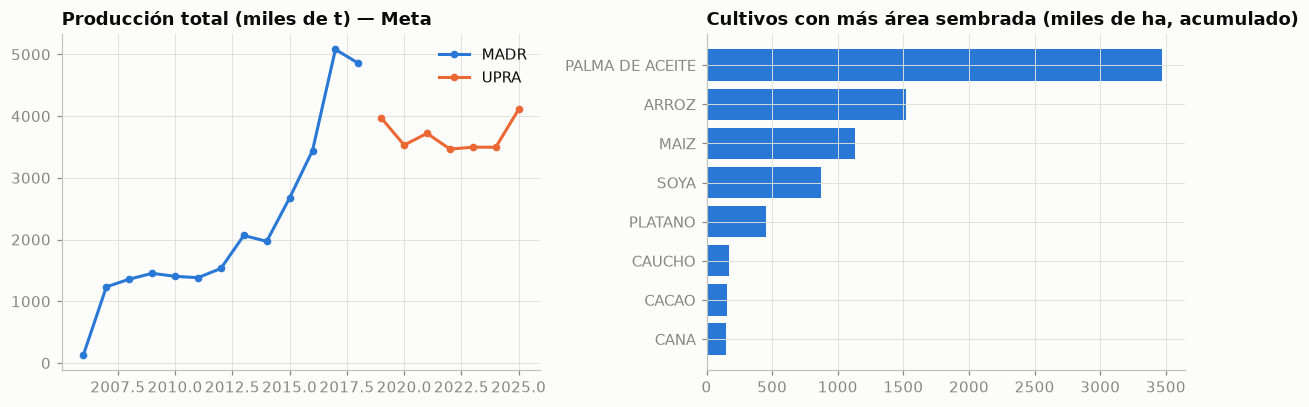

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
anual = eva.groupby(["anio", "fuente"])["produccion_t"].sum().unstack()
for f, color in [("MADR", AZUL), ("UPRA", NARANJA)]:
    if f in anual:
        a1.plot(anual.index, anual[f] / 1e3, color=color, marker="o", ms=4, label=f)
a1.set_title(f"Producción total (miles de t) — {DEPARTAMENTO or 'país'}"); a1.legend()
top = eva.groupby("cultivo")["area_sembrada"].sum().sort_values().tail(8) / 1e3
a2.barh(top.index, top.values, color=AZUL); a2.set_title("Cultivos con más área sembrada (miles de ha, acumulado)")
plt.tight_layout(); plt.show()

*(Se completa al ejecutar.)*

## 8. Guardar

In [10]:
ruta = guardar(eva, etiqueta("eva_agricola", DEPARTAMENTO or "pais", CULTIVO))

Guardado: datos\eva_agricola_meta.parquet (9.479 filas × 15 columnas)


## Siguientes pasos

1. Cargue la base en otro cuaderno: `df = pd.read_parquet("datos/eva_agricola_meta.parquet")` (o `read_csv` / `read_excel` según el `FORMATO`).
2. Defina la **pregunta** y la **variable objetivo** (vea «Ideas para un modelo de machine learning»).
3. Revise faltantes, valores extremos y tipos de variables antes de modelar (clase 2.1, ingeniería de características).
4. Parta en entrenamiento y prueba **antes** de transformar, y compare su modelo con una **línea base** sencilla.